# Hafta 2 · Makine Öğrenmesinin Temelleri

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde ölçekleme, eksik veri doldurma, one-hot kodlama, katmanlı bölme, korelasyon ve PCA işlemlerini çalıştırıp ders notlarındaki elle yapılmış hesaplarla karşılaştıracaksınız.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Min-maks normalizasyonu ve z-skoru (Çözümlü Örnek 2.2)
İstatistikler (min, maks, ortalama, standart sapma) **yalnızca eğitim kümesinden** hesaplanır; test verisi bu istatistiklerle dönüştürülür.

In [2]:
import numpy as np

yas = np.array([20, 25, 30, 35, 40])     # eğitim kümesi
mn, mx = yas.min(), yas.max()
mu, sigma = yas.mean(), yas.std()        # std: n'ye böler
print("min-maks:", (yas - mn) / (mx - mn))
print("z-skoru :", np.round((yas - mu) / sigma, 3))
x_test = 50                              # test kümesinden
print("test    :", (x_test - mn) / (mx - mn),
      round((x_test - mu) / sigma, 3))

min-maks: [0.   0.25 0.5  0.75 1.  ]
z-skoru : [-1.414 -0.707  0.     0.707  1.414]
test    : 1.5 2.828


## 2. Ölçekleme neden önemli? (Çözümlü Örnek 2.3)
Öklid uzaklığını önce ham değerlerle, sonra verilen aralıklara göre min-maks ölçeklemesiyle hesaplayalım.

In [3]:
A = np.array([25, 30000])                # (yaş, maaş)
B = np.array([55, 31000])
C = np.array([26, 40000])
d = lambda p, q: round(float(np.linalg.norm(p - q)), 3)
print("ham    :", d(A, B), d(A, C))      # d(A,B), d(A,C)

alt, ust = np.array([20, 10000]), np.array([60, 100000])
s = lambda p: (p - alt) / (ust - alt)    # min-maks ölçekleme
print("ölçekli:", d(s(A), s(B)), d(s(A), s(C)))

ham    : 1000.45 10000.0
ölçekli: 0.75 0.114


## 3. pandas ile eksik veri ve one-hot kodlama
Eksik yaş, bilinen yaşların ortalamasıyla doldurulur; nominal `sehir` sütunu one-hot kodlanır.

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    "yas":   [22, None, 30, 26, 35, 41, 29, 38],
    "sehir": ["Iğdır", "Kars", "Van", "Iğdır", "Van", "Kars", "Iğdır", "Van"],
    "aldi":  [1, 0, 1, 0, 1, 0, 0, 1]})

df["yas"] = df["yas"].fillna(df["yas"].mean())        # eksik değeri ortalamayla doldur
df = pd.get_dummies(df, columns=["sehir"], dtype=int)  # one-hot kodlama
df.head()

,yas,aldi,sehir_Iğdır,sehir_Kars,sehir_Van
0,22.000000,1,1,0,0
1,31.571429,0,0,1,0
2,30.000000,1,0,0,1
3,26.000000,0,1,0,0
4,35.000000,1,0,0,1


## 4. Katmanlı bölme ve sızıntısız ölçekleme

In [5]:
X, y = df.drop(columns="aldi"), df["aldi"]
# katmanlı bölme: sınıf oranları korunur
X_egt, X_test, y_egt, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

# ölçekleme istatistikleri YALNIZCA eğitim kümesinden
olcek = StandardScaler().fit(X_egt[["yas"]])
X_egt["yas"] = olcek.transform(X_egt[["yas"]])
X_test["yas"] = olcek.transform(X_test[["yas"]])
print(X_egt.shape, X_test.shape)        # (6, 4) (2, 4)

(6, 4) (2, 4)


## 5. Pearson korelasyonu (Çözümlü Örnek 2.5 ve Soru 13)
Korelasyon ölçekten bağımsızdır ve yalnızca **doğrusal** ilişkiyi ölçer.

In [6]:
x = np.array([1, 2, 3, 4, 5])      # çalışma süresi (saat)
y = np.array([2, 4, 5, 4, 5])      # proje puanı
r = np.corrcoef(x, y)[0, 1]
print("r      =", round(r, 3), "  r² =", round(r ** 2, 3))

# ölçek değişince r değişmez
print("10·y   =", round(np.corrcoef(x, 10 * y)[0, 1], 3))

# güçlü ama doğrusal olmayan ilişki: t ve t²
t = np.arange(-3, 4)
print("t ve t²=", round(np.corrcoef(t, t ** 2)[0, 1], 3))

r      = 0.775   r² = 0.6
10·y   = 0.775
t ve t²= 0.0


### Ek: Dengesiz veride sınıf ağırlıkları
10 000 işlemin 100'ü sahte. `class_weight='balanced'` ağırlıkları w_c = n / (k · n_c) formülüyle hesaplar.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

etiket = np.array([0] * 9900 + [1] * 100)       # 0: normal, 1: sahte
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=etiket)
print("w_normal =", round(w[0], 3), "  w_sahte =", w[1])

w_normal = 0.505   w_sahte = 50.0


## 6. PCA ile boyut indirgeme
Iris verisindeki 4 öznitelik standartlaştırılır ve varyansın en büyük olduğu 2 yöne izdüşürülür.

açıklanan varyans: [0.73  0.229]
toplam: 0.958


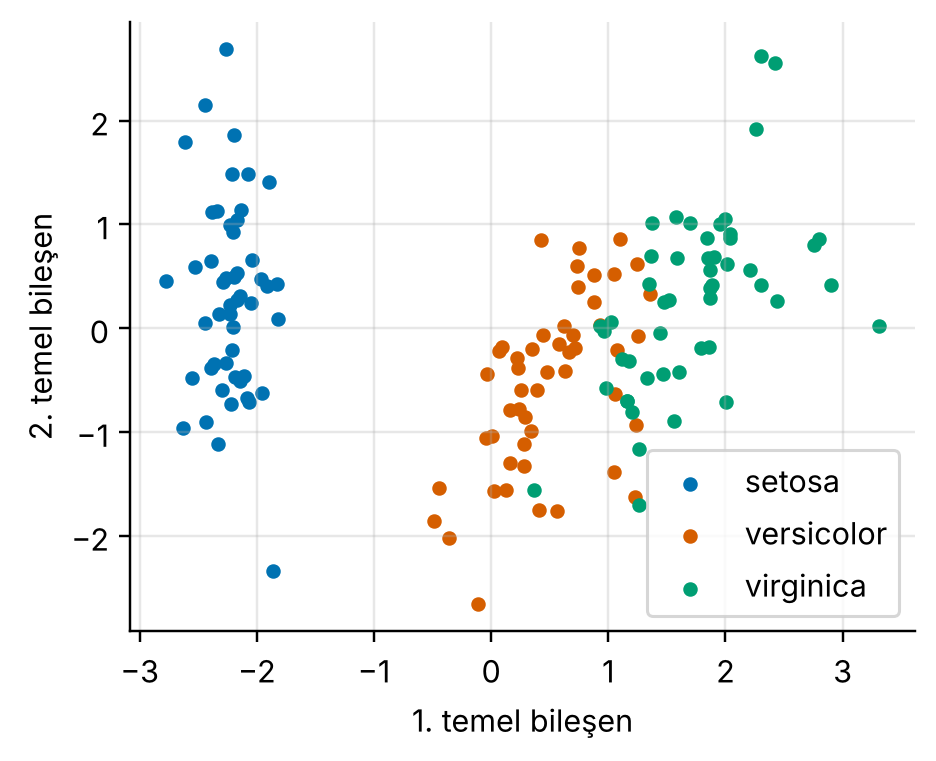

In [8]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X, y = load_iris(return_X_y=True)   # 150 × 4
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(Z)
X2 = pca.transform(Z)               # 4 → 2 boyut
oran = pca.explained_variance_ratio_
print("açıklanan varyans:", oran.round(3))
print("toplam:", oran.sum().round(3))
plt.figure(figsize=(4.6, 3.6))
turler = ["setosa", "versicolor", "virginica"]
for k, ad in enumerate(turler):
    plt.scatter(*X2[y == k].T, s=14, label=ad)
plt.xlabel("1. temel bileşen")
plt.ylabel("2. temel bileşen")
plt.legend(); plt.show()

### Alıştırma (Değerlendirme Soruları 9 ve 13)
Önce kâğıt üzerinde çözün, sonra çalıştırıp karşılaştırın.

In [ ]:
v = np.array([10, 20, 30, 40, 50])
print("min-maks:", (v - v.min()) / (v.max() - v.min()))
print("z-skoru :", np.round((v - v.mean()) / v.std(), 3))

x2, y2 = np.array([2, 4, 6, 8]), np.array([1, 3, 2, 6])
print("r =", round(np.corrcoef(x2, y2)[0, 1], 3))